# Exploratory Data Analysis

**Project objective:** predict, per patient, the `Murmur` label (*Present / Unknown / Absent*) from the phonocardiograms (PCG).

0. What data does the dataset contain, how is it organised, and which of it can be a model input?
1. How are the labels distributed, and what *baseline* do we have?
2. What does a murmur look like: where, when in the cardiac cycle, at which frequencies?
3. What are the recordings like: duration, auscultation locations, quality, *sample rate*?
4. What does all this mean for the pre-processing?

In [1]:
import sys; sys.path.insert(0, '..')
from pathlib import Path
import hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa, librosa.display, scipy.signal as ss
from tqdm.auto import tqdm
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.width', 140); pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Present': '#d62728', 'Unknown': '#7f7f7f', 'Absent': '#1f77b4'}
FIG_DIR = Path('../results/eda'); FIG_DIR.mkdir(parents=True, exist_ok=True)
save = lambda name: plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 0. Dataset structure
Before using the project's auxiliar functions (`src/`), we look at the files as they come from the website, using only `pathlib`, `pandas` and `soundfile`.
We're looking for:
- which files exist and what each type contains;
- how they relate to each other and whether they are consistent;
- **which information can be a model input**.

In [ ]:
# the dataset must be in data/circor/
CANDIDATES = [Path('../data/circor')]
RAW = next(p for p in CANDIDATES if (p / 'training_data.csv').exists())
TD = RAW / 'training_data'
print('dataset at', RAW.resolve(), '\n')
for p in sorted(RAW.iterdir()):
    if p.is_dir():
        fs = list(p.iterdir())
        print(f'{p.name + "/":22s} {len(fs):6d} files  {sum(f.stat().st_size for f in fs) / 1e6:7.1f} MB')
    else:
        print(f'{p.name:22s} {"":6s}        {p.stat().st_size / 1e3:7.1f} KB')

dataset at C:\Users\rafa\Documents\FCUP\AC 2\FCUP-DL-ML2\data\the-circor-digiscope-phonocardiogram-dataset-1.0.3 

LICENSE.txt                             20.4 KB
RECORDS                                 72.8 KB
SHA256SUMS.txt                         957.3 KB
training_data/          10431 files    584.8 MB
training_data.csv                      117.0 KB


### 0.1 Files inside `training_data/`

In [3]:
files = pd.DataFrame({'name': [f.name for f in TD.iterdir()], 'bytes': [f.stat().st_size for f in TD.iterdir()]})
files['ext'] = files.name.str.rsplit('.', n=1).str[1]
files['stem'] = files.name.str.rsplit('.', n=1).str[0]
summary = files.groupby('ext').agg(files=('name', 'size'), MB=('bytes', lambda b: round(b.sum() / 1e6, 1)),
                                   example=('name', 'first'))
summary['one per'] = summary.index.map({'wav': 'recording', 'hea': 'recording', 'tsv': 'recording', 'txt': 'patient'})
summary['content'] = summary.index.map({
    'wav': 'audio (phonocardiogram)',
    'hea': 'WFDB header of the audio (fs, n samples, location)',
    'tsv': 'manual segmentation: S1 / systole / S2 / diastole',
    'txt': 'list of recordings + clinical data of the patient'})
display(summary)

# naming convention: {patient}_{location}[_{n}].{ext} for recordings, {patient}.txt per patient
rec_files = files[files.ext == 'wav'].stem
parts = rec_files.str.split('_')
print('locations found in file names:', parts.str[1].value_counts().to_dict())
print('repeated recordings at the same location (suffix _1, _2, ...):', (parts.str.len() == 3).sum())

,files,MB,example,one per,content
ext,,,,,
hea,3163,0.2,13918_AV.hea,recording,"WFDB header of the audio (fs, n samples, location)"
tsv,3163,5.2,13918_AV.tsv,recording,manual segmentation: S1 / systole / S2 / diastole
txt,942,0.6,13918.txt,patient,list of recordings + clinical data of the patient
wav,3163,578.8,13918_AV.wav,recording,audio (phonocardiogram)


locations found in file names: {'MV': 861, 'AV': 800, 'PV': 766, 'TV': 732, 'Phc': 4}
repeated recordings at the same location (suffix _1, _2, ...): 43


**Naming convention.** Each recording is named `{patient}_{location}.wav`, or `{patient}_{location}_{n}.wav` when the same location was recorded more than once.
The auscultation locations are AV (aortic), PV (pulmonary), TV (tricuspid), MV (mitral) and Phc (other). Each recording has three files with the same name
(`.wav`, `.hea`, `.tsv`), and each patient has one `{patient}.txt`.

### 0.2 Top-level files: `RECORDS`, `LICENSE.txt`, `SHA256SUMS.txt`

In [ ]:
records = (RAW / 'RECORDS').read_text().split()
print(f'RECORDS: {len(records)} lines, e.g.: {records[:3]}')
print('LICENSE:', (RAW / 'LICENSE.txt').read_text().splitlines()[0])

sums = pd.read_csv(RAW / 'SHA256SUMS.txt', sep=' ', header=None, names=['sha256', 'file'])
print(f'SHA256SUMS: {len(sums)} files with a checksum, by type:',
      sums.file.str.rsplit('.', n=1).str[-1].value_counts().to_dict())

# integrity: compare the SHA-256 of each file with the published one (VERIFY_ALL=True checks all ~10 000)
VERIFY_ALL = False
check = sums if VERIFY_ALL else pd.concat([sums[~sums.file.str.contains('/')], sums.sample(100, random_state=0)])
ok = bad = missing = 0
for h, f in zip(check.sha256, check.file):
    p = RAW / f
    if not p.exists(): missing += 1; continue
    if hashlib.sha256(p.read_bytes()).hexdigest() == h: ok += 1
    else: bad += 1; print('checksum mismatch:', f)
print(f'checked {ok + bad}: {ok} correct, {bad} corrupted, {missing} missing')

RECORDS: 3163 lines, e.g.: ['training_data/2530_AV', 'training_data/2530_MV', 'training_data/2530_PV']
LICENSE: # ODC Attribution License (ODC-By)
SHA256SUMS: 10434 files with a checksum, by type: {'hea': 3163, 'tsv': 3163, 'wav': 3163, 'txt': 943, 'RECORDS': 1, 'csv': 1}
checked 10434: 10434 correct, 0 corrupted, 0 missing


- `RECORDS` is the official index of the recordings (`training_data/{name}`, without extension).
- `LICENSE.txt`: ODC-By licence. We may use and modify the data as long as we cite the source (dataset and reference paper in the slides).
- `SHA256SUMS.txt` lets us confirm that no file was corrupted during the download.

### 0.3 Per recording: `.wav`, `.hea`, `.tsv`

In [5]:
ex = '13918_TV' if (TD / '13918_TV.wav').exists() else sorted(TD.glob('*.wav'))[0].stem
print(f'--- {ex}.hea'); print((TD / f'{ex}.hea').read_text())
print(f'--- {ex}.wav'); print(sf.info(TD / f'{ex}.wav'), '\n')
print(f'--- {ex}.tsv (first lines)')
pd.read_csv(TD / f'{ex}.tsv', sep='\t', header=None, names=['start (s)', 'end (s)', 'state']).head(6)

--- 13918_TV.hea
13918_TV 1 4000 26368
13918_TV.wav 16+44 1 16 0 0 0 0 TV

--- 13918_TV.wav
..\data\the-circor-digiscope-phonocardiogram-dataset-1.0.3\training_data\13918_TV.wav
samplerate: 4000 Hz
channels: 1
duration: 6.592 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16] 

--- 13918_TV.tsv (first lines)


,start (s),end (s),state
0,0.000000,0.108500,0
1,0.108500,0.240176,1
2,0.240176,0.360176,2
3,0.360176,0.500176,3
4,0.500176,0.700176,4
5,0.700176,0.820176,1


- **`.wav`**: the phonocardiogram, one channel, 16-bit PCM. It is **the only signal** in the dataset.
- **`.hea`**: header in PhysioNet's WFDB format. Line 1 is `name n_signals sampling_rate n_samples`.
  Line 2 is `file format(16 bits + 44-byte header) gain resolution ... location`. It adds nothing beyond the `.wav` and the file name.
- **`.tsv`**: manual segmentation as `start, end, state` (0 = unannotated, 1 = S1, 2 = systole, 3 = S2, 4 = diastole).
  It is an **expert annotation**, not part of the signal.

In [6]:
# does every .hea match its .wav?
rows = []
for f in tqdm(sorted(TD.glob('*.hea')), desc='.hea'):
    l1, l2 = f.read_text().splitlines()[:2]
    name, n_sig, fs, n_samp = l1.split()
    info = sf.info(TD / f'{name}.wav')
    rows.append(dict(recording=name, n_sig=int(n_sig), fs=int(fs), n_samples=int(n_samp), loc_hea=l2.split()[-1],
                     sr_wav=info.samplerate, frames_wav=info.frames, channels=info.channels, subtype=info.subtype))
hea = pd.DataFrame(rows)
print('sampling rate (.hea / .wav):', hea.fs.unique(), '/', hea.sr_wav.unique(), '| channels:', hea.channels.unique(), '| format:', list(hea.subtype.unique()))
print('same number of samples in .hea and .wav:', (hea.n_samples == hea.frames_wav).all())
print('location in .hea equals the one in the file name:', (hea.loc_hea == hea.recording.str.split('_').str[1]).all())
print(f'duration: {(hea.frames_wav / hea.sr_wav).min():.1f}–{(hea.frames_wav / hea.sr_wav).max():.1f} s')

.hea:   0%|          | 0/3163 [00:00<?, ?it/s]

sampling rate (.hea / .wav): [4000] / [4000] | channels: [1] | format: ['PCM_16']
same number of samples in .hea and .wav: True
location in .hea equals the one in the file name: True
duration: 5.2–64.5 s


### 0.4 Per patient: `{patient}.txt` and `training_data.csv`

In [7]:
pid_ex = int(ex.split('_')[0])
print(f'--- {pid_ex}.txt'); print((TD / f'{pid_ex}.txt').read_text())

--- 13918.txt
13918 4 4000
AV 13918_AV.hea 13918_AV.wav 13918_AV.tsv
PV 13918_PV.hea 13918_PV.wav 13918_PV.tsv
TV 13918_TV.hea 13918_TV.wav 13918_TV.tsv
MV 13918_MV.hea 13918_MV.wav 13918_MV.tsv
#Age: Child
#Sex: Male
#Height: 98.0
#Weight: 15.9
#Pregnancy status: False
#Murmur: Present
#Murmur locations: TV
#Most audible location: TV
#Systolic murmur timing: Holosystolic
#Systolic murmur shape: Plateau
#Systolic murmur grading: I/VI
#Systolic murmur pitch: Low
#Systolic murmur quality: Blowing
#Diastolic murmur timing: nan
#Diastolic murmur shape: nan
#Diastolic murmur grading: nan
#Diastolic murmur pitch: nan
#Diastolic murmur quality: nan
#Outcome: Abnormal
#Campaign: CC2015
#Additional ID: nan



In [8]:
def parse_txt(f):
    lines = f.read_text().strip().splitlines()
    pid, n, fs = lines[0].split()
    recs = [l.split() for l in lines[1:1 + int(n)]]
    meta = dict(l[1:].split(': ', 1) for l in lines[1 + int(n):])
    return dict(pid=int(pid), n_rec=int(n), fs=int(fs), recordings=[r[2][:-4] for r in recs],
                locations='+'.join(r[0] for r in recs), **meta)

txt = pd.DataFrame([parse_txt(f) for f in tqdm(sorted(TD.glob('*.txt')), desc='.txt')]).set_index('pid')
csv = pd.read_csv(RAW / 'training_data.csv').set_index('Patient ID')
print(f'{len(txt)} .txt files | training_data.csv: {csv.shape[0]} rows × {csv.shape[1] + 1} columns (incl. Patient ID)')

# do the .txt and the .csv hold the same information?
def as_str(s):
    fmt = (lambda v: str(int(v))) if s.name == 'Additional ID' else str   # IDs in the .txt have no '.0'
    return s.map(lambda v: 'nan' if pd.isna(v) else fmt(v))
cols = [c for c in csv.columns if c in txt.columns]
diff = {c: (as_str(csv.loc[txt.index, c]) != txt[c]).sum() for c in cols}
print('columns compared:', len(cols), '| differences:', sum(diff.values()))
print('locations in .txt == csv "Recording locations:":', (txt.locations == csv.loc[txt.index, 'Recording locations:']).all())

.txt:   0%|          | 0/942 [00:00<?, ?it/s]

942 .txt files | training_data.csv: 942 rows × 23 columns (incl. Patient ID)
columns compared: 21 | differences: 0
locations in .txt == csv "Recording locations:": True


Each patient's `.txt` holds **the same information** as the patient's row in `training_data.csv`, plus the list of their files.
We therefore use the CSV, which is more convenient, and the `.txt` only to confirm consistency.

### 0.5 Data dictionary of `training_data.csv` and what can be a model input

In [9]:
CAT = {
    'Recording locations:': ('acquisition', 'recorded locations; also known from the file names'),
    'Age': ('demographics', 'not an input'), 'Sex': ('demographics', 'not an input'),
    'Height': ('demographics', 'not an input'), 'Weight': ('demographics', 'not an input'),
    'Pregnancy status': ('demographics', 'not an input'),
    'Murmur': ('LABEL (target)', 'what we predict, one per patient'),
    'Murmur locations': ('murmur annotation', 'only to build per-recording training labels'),
    'Most audible location': ('murmur annotation', 'exploration only'),
    'Outcome': ('other label', 'DO NOT use: final diagnosis, correlated with Murmur'),
    'Campaign': ('acquisition', 'exploration only'),
    'Additional ID': ('identifier', 'only for the split (same child in both campaigns)'),
}
for c in csv.columns:
    if c.startswith(('Systolic', 'Diastolic')): CAT[c] = ('murmur annotation', 'exploration only')

dic = pd.DataFrame({
    'dtype': csv.dtypes.astype(str),
    'missing (%)': (100 * csv.isna().mean()).round(1),
    'distinct': csv.nunique(),
    'examples': [', '.join(map(str, csv[c].dropna().unique()[:4])) for c in csv.columns],
    'category': [CAT[c][0] for c in csv.columns],
    'use in the project': [CAT[c][1] for c in csv.columns],
})
dic.index.name = 'column'
display(dic)
print('Patient ID: identifier,', csv.index.nunique(), 'unique patients')

,dtype,missing (%),distinct,examples,category,use in the project
column,,,,,,
Recording locations:,str,0.0,28,"AV+PV+TV+MV, AV+MV, PV+TV+MV, AV",acquisition,recorded locations; also known from the file names
Age,str,7.9,4,"Child, Adolescent, Infant, Neonate",demographics,not an input
Sex,str,0.0,2,"Female, Male",demographics,not an input
Height,float64,12.3,132,"98.0, 103.0, 115.0, 87.0",demographics,not an input
Weight,float64,11.1,435,"15.9, 13.1, 19.1, 11.2",demographics,not an input
Pregnancy status,bool,0.0,2,"False, True",demographics,not an input
Murmur,str,0.0,3,"Absent, Present, Unknown",LABEL (target),"what we predict, one per patient"
Murmur locations,str,81.0,17,"AV+MV+PV+TV, TV, MV+TV, MV+PV+TV",murmur annotation,only to build per-recording training labels
Most audible location,str,81.0,4,"TV, PV, MV, AV",murmur annotation,exploration only


Patient ID: identifier, 942 unique patients


In [10]:
# why Outcome cannot be used: it is strongly associated with the target
pd.crosstab(csv.Outcome, csv.Murmur)[['Present', 'Unknown', 'Absent']]

Murmur,Present,Unknown,Absent
Outcome,,,
Abnormal,150,43,263
Normal,29,25,432


### 0.6 Consistency between files

In [11]:
stems = {e: set(files.loc[files.ext == e, 'stem']) for e in ['wav', 'hea', 'tsv', 'txt']}
wav_pids = {int(s.split('_')[0]) for s in stems['wav']}
checks = {
    'every .wav has a .hea and a .tsv': stems['wav'] == stems['hea'] == stems['tsv'],
    'RECORDS lists exactly the .wav files': {r.split('/')[-1] for r in records} == stems['wav'],
    'every CSV patient has a .txt': set(csv.index) == {int(s) for s in stems['txt']},
    'every CSV patient has recordings': set(csv.index) == wav_pids,
    'recordings listed in .txt exist': all((TD / f'{r}.wav').exists() for rs in txt.recordings for r in rs),
    'n .wav per patient == n in .txt': (pd.Series([int(s.split('_')[0]) for s in stems['wav']]).value_counts()
                                        .reindex(txt.index) == txt.n_rec).all(),
    'Additional ID points to CSV patients': csv['Additional ID'].dropna().astype(int).isin(csv.index).all(),
}
pd.Series(checks, name='ok').to_frame()

,ok
every .wav has a .hea and a .tsv,True
RECORDS lists exactly the .wav files,True
every CSV patient has a .txt,True
every CSV patient has recordings,True
recordings listed in .txt exist,True
n .wav per patient == n in .txt,True
Additional ID points to CSV patients,True


### 0.7 Summary: what we have and what goes into the models

| data | where | role in the project |
|---|---|---|
| **phonocardiogram** | `.wav` (4 kHz, 1 channel, 5–65 s) | **the only model input** (MLP and CNN) |
| recording location (AV/PV/TV/MV/Phc) | file name / `.hea` | identifies the recording; **not an input** for now |
| `Murmur` | `training_data.csv` / `.txt` | **label to predict**, one per patient |
| `Murmur locations` | `training_data.csv` | only to create per-recording training labels (where the murmur is heard); never an input |
| S1/systole/S2/diastole segmentation | `.tsv` | exploration only: it is a manual annotation and the hidden data may not include it |
| age, sex, height, weight, pregnancy | `training_data.csv` | exploration only; **not an input** |
| murmur characteristics (timing, shape, grade, pitch, quality, most audible location) | `training_data.csv` | exploration only (they describe the murmur and only exist when there is one) |
| `Outcome` | `training_data.csv` | **never use**: it is another diagnosis and strongly associated with `Murmur` |
| `Campaign` | `training_data.csv` | exploration only |
| `Additional ID` | `training_data.csv` | only for the split: the same child stays in the same fold |

In [12]:
from src.data import (load_patients, load_recordings, load_split, load_segmentation,
                      segmentation_stats, DATA_DIR, WAV_DIR, CLASSES)
from src.metrics import weighted_accuracy
from src import features as F
assert DATA_DIR.resolve() == RAW.resolve()   # src/data.py finds the same folder as section 0

## 1. Patients and labels

942 patients


,count,pct
Murmur,,
Present,179,19.0
Unknown,68,7.2
Absent,695,73.8


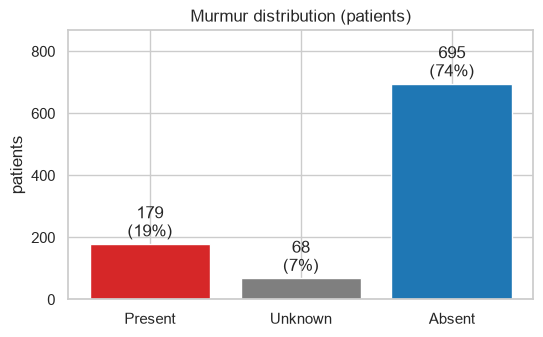

In [13]:
pat = load_patients()
print(len(pat), 'patients')
counts = pat['Murmur'].value_counts().reindex(CLASSES)
display(counts.to_frame().assign(pct=lambda d: (100 * d['count'] / d['count'].sum()).round(1)))

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
ax.bar_label(bars, labels=[f'{v}\n({100*v/counts.sum():.0f}%)' for v in counts.values], padding=2)
ax.set(title='Murmur distribution (patients)', ylabel='patients', ylim=(0, counts.max() * 1.25))
save('class_distribution'); plt.show()

In [14]:
# trivial baselines with the official metric
for c in CLASSES:
    print(f'always {c:8s} WA = {weighted_accuracy(pat.Murmur, [c] * len(pat)):.3f}')

always Present  WA = 0.499
always Unknown  WA = 0.114
always Absent   WA = 0.387


**Reading.** The imbalance is strong (≈74 % *Absent*, 7 % *Unknown*). With the *weighted accuracy* the logic flips:
always predicting *Absent* gives only ≈0.39, always predicting *Present* gives ≈0.50. This is the minimum a model has to beat.
In practice, missing a *Present* costs 5× more than a false alarm, which justifies class weights in the loss
and a decision threshold tuned on validation.

## 2. Demographics, campaigns and repeated patients

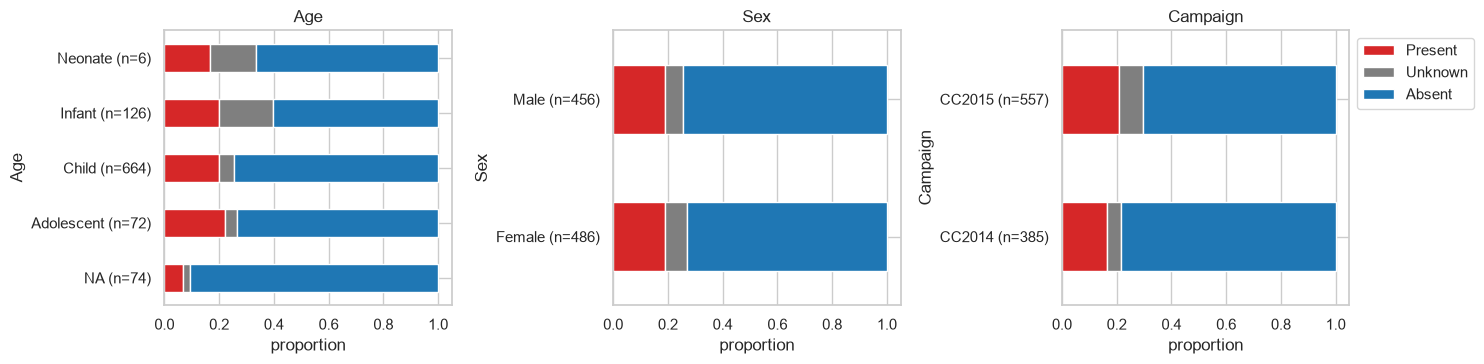

Pregnant: 70 | age missing: 74


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ['Age', 'Sex', 'Campaign']):
    ct = pd.crosstab(pat[col].fillna('NA'), pat['Murmur'], normalize='index')[CLASSES]
    if col == 'Age': ct = ct.reindex(['NA', 'Adolescent', 'Child', 'Infant', 'Neonate'])
    ct.plot.barh(stacked=True, color=[PALETTE[c] for c in CLASSES], ax=ax, legend=ax is axes[-1])
    n = pat[col].fillna('NA').value_counts()
    ax.set_yticklabels([f'{t.get_text()} (n={n[t.get_text()]})' for t in ax.get_yticklabels()])
    ax.set(title=col, xlabel='proportion')
axes[-1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); save('demographics_vs_murmur'); plt.show()

print('Pregnant:', pat['Pregnancy status'].sum(), '| age missing:', pat.Age.isna().sum())

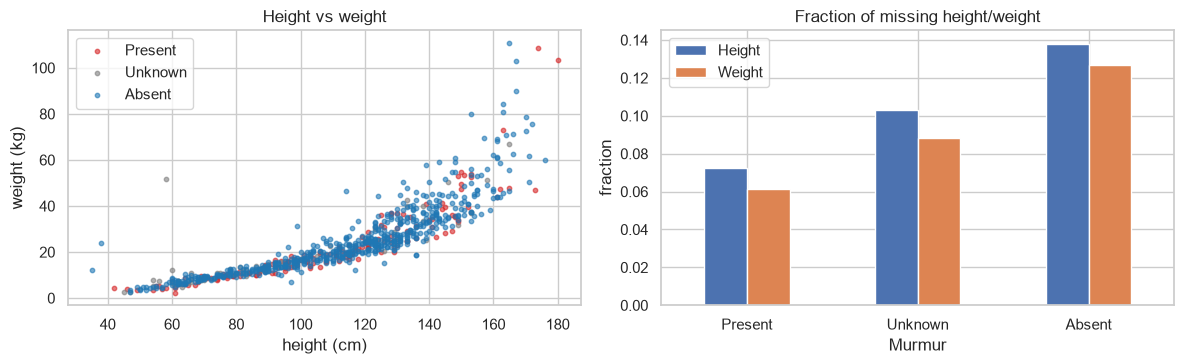

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for c in CLASSES:
    sub = pat[pat.Murmur == c]
    ax[0].scatter(sub.Height, sub.Weight, s=10, alpha=.6, color=PALETTE[c], label=c)
ax[0].set(xlabel='height (cm)', ylabel='weight (kg)', title='Height vs weight'); ax[0].legend()
pat[['Height', 'Weight']].isna().groupby(pat.Murmur).mean().reindex(CLASSES).plot.bar(ax=ax[1], rot=0)
ax[1].set(title='Fraction of missing height/weight', ylabel='fraction')
plt.tight_layout(); plt.show()

In [17]:
# Additional ID: the same child seen in both campaigns -> same group in the split (src/make_split.py)
rep = pat[pat['Additional ID'].notna()]
print(len(rep), 'patients with an Additional ID')
pairs = rep.reset_index()[['Patient ID', 'Additional ID', 'Murmur']]
pairs['Murmur (other campaign)'] = pairs['Additional ID'].astype(int).map(pat.Murmur)
pd.crosstab(pairs['Murmur'], pairs['Murmur (other campaign)'].fillna('not in the public data'))

140 patients with an Additional ID


Murmur (other campaign),Absent,Present,Unknown
Murmur,,,
Absent,72,4,6
Present,4,36,5
Unknown,6,5,2


**Reading.**
- *Infants* have far more *Unknown* (small children move and cry, so more noise is expected).
  The age group explains part of *Unknown*, but we do not use demographics as an input,
  and age is missing for ~8 % of the patients.
- Campaign CC2015 has more *Present* and *Unknown* than CC2014. The stratified split keeps the overall class proportions,
  but it is worth checking whether errors concentrate in one campaign.
- The 140 patients with an `Additional ID` are 70 children seen in both campaigns. They stay in the same fold to avoid leakage.
  The table shows that the label **does not always agree** between the two visits (each pair appears twice, once in each row).
  The label itself is noisy, especially around *Unknown*, and this caps the achievable *accuracy*.

## 3. What does a murmur look like? (*Present* patients)
The CSV describes each murmur: in which phase of the cycle it appears, its shape, intensity (*grading*), pitch and quality.
This tells us which time-frequency pattern the models have to find.

systolic murmur: 178 | diastolic: 5 | both: 4 of 179


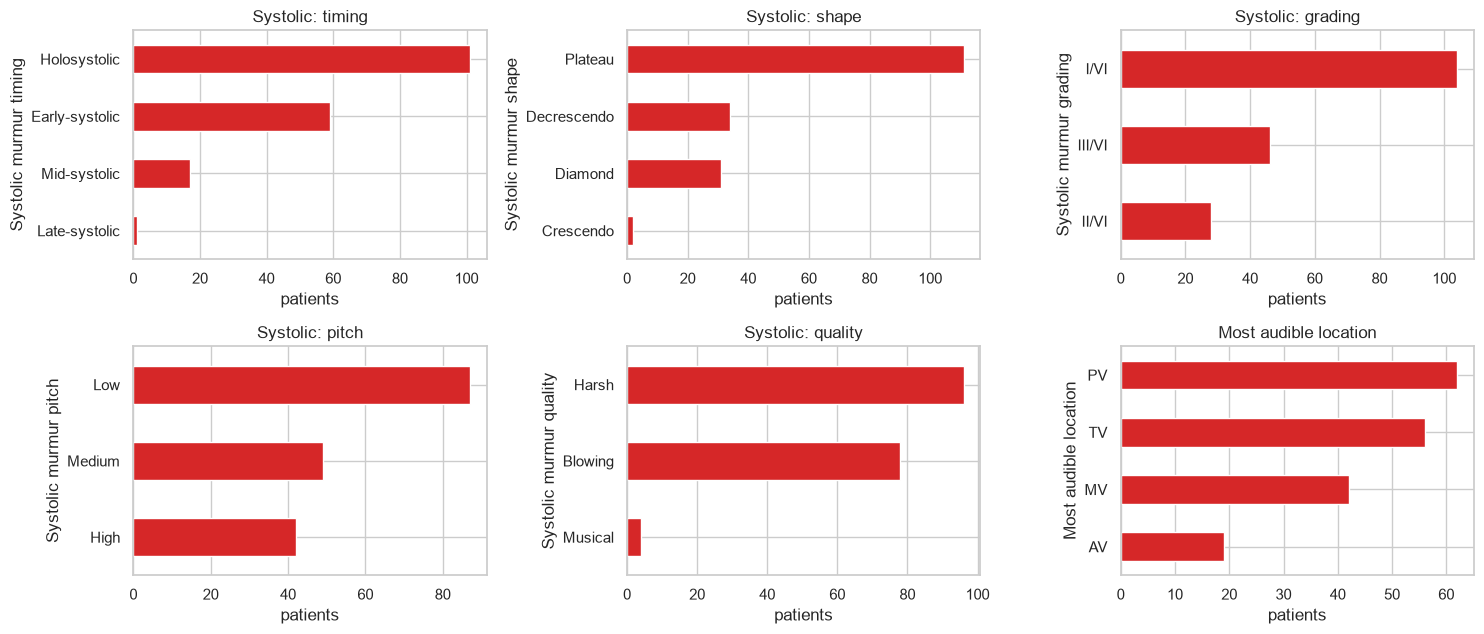

In [18]:
present = pat[pat.Murmur == 'Present']
print('systolic murmur:', present['Systolic murmur timing'].notna().sum(),
      '| diastolic:', present['Diastolic murmur timing'].notna().sum(),
      '| both:', (present['Systolic murmur timing'].notna() & present['Diastolic murmur timing'].notna()).sum(),
      'of', len(present))

cols = ['Systolic murmur timing', 'Systolic murmur shape', 'Systolic murmur grading',
        'Systolic murmur pitch', 'Systolic murmur quality', 'Most audible location']
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, col in zip(axes.flat, cols):
    present[col].value_counts().plot.barh(ax=ax, color='#d62728')
    ax.set(title=col.replace('Systolic murmur ', 'Systolic: '), xlabel='patients'); ax.invert_yaxis()
plt.tight_layout(); save('murmur_characteristics'); plt.show()

**Reading.**
- Almost all murmurs are **systolic** (between S1 and S2). Diastolic murmurs are very rare.
- *Holosystolic* (the whole systole) and *early-systolic* dominate, with a *plateau* shape (constant intensity),
  mostly grade I/VI (**very faint**) and *low* pitch, with *harsh* or *blowing* quality.
  A typical murmur is a faint, broadband noise filling the interval between S1 and S2.
- The location where it is heard best is mostly PV or TV. AV is the least frequent.
- Consequence for the model: the input window must contain **complete cardiac cycles**, so that what happens between S1 and S2 is visible.
  That is why we should use 4 s windows instead of short frames. The time resolution must also be fine (10 ms) to separate S1/systole/S2.

## 4. Recordings: number, locations, duration

In [19]:
rec = load_recordings()
info = [sf.info(p) for p in tqdm(rec.path, desc='headers')]
rec['sr'] = [i.samplerate for i in info]
rec['duration'] = [i.duration for i in info]
rec['fold'] = rec.patient_id.map(load_split().fold)
print(len(rec), 'recordings;', rec.patient_id.nunique(), 'patients; sample rates:', rec.sr.unique())
print(rec.groupby('patient_id').size().value_counts().sort_index().rename('patients with n recordings').to_string())
print('\nrepeated locations (files *_n.wav):', rec.recording.str.count('_').gt(1).sum())

headers:   0%|          | 0/3163 [00:00<?, ?it/s]

3163 recordings; 942 patients; sample rates: [4000]
1     62
2    156
3    123
4    588
5     10
6      3

repeated locations (files *_n.wav): 43


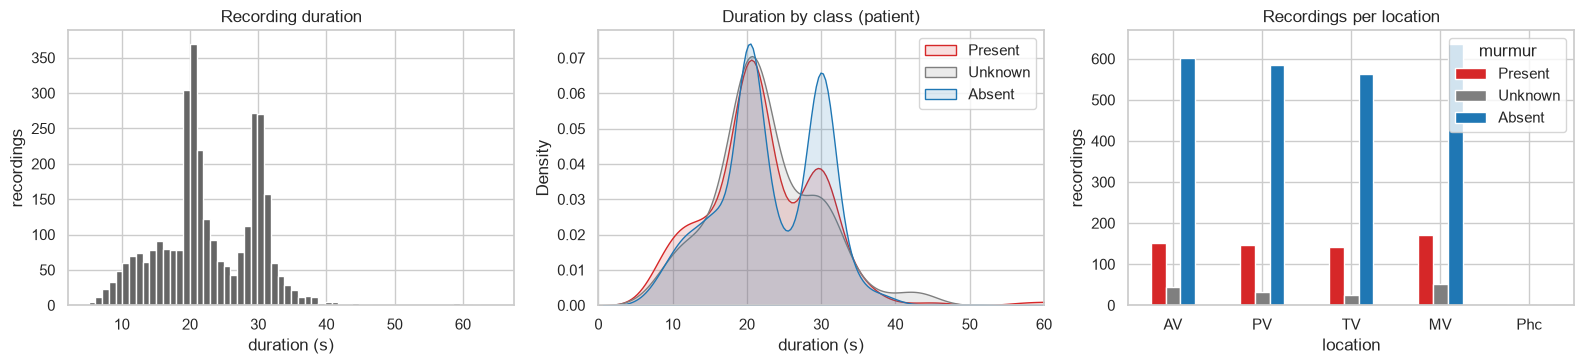

count    3163.0
mean       22.9
std         7.3
min         5.2
25%        19.1
50%        21.5
75%        29.4
max        64.5


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
rec.duration.hist(bins=60, ax=ax[0], color='0.4'); ax[0].set(xlabel='duration (s)', ylabel='recordings', title='Recording duration')
for c in CLASSES:
    sns.kdeplot(rec.loc[rec.murmur == c, 'duration'], ax=ax[1], color=PALETTE[c], label=c, fill=True, alpha=.15)
ax[1].set(xlabel='duration (s)', xlim=(0, 60), title='Duration by class (patient)'); ax[1].legend()
pd.crosstab(rec.location, rec.murmur).reindex(index=['AV', 'PV', 'TV', 'MV', 'Phc'], columns=CLASSES).dropna(how='all').plot.bar(
    ax=ax[2], color=[PALETTE[c] for c in CLASSES], rot=0)
ax[2].set(title='Recordings per location', ylabel='recordings')
plt.tight_layout(); save('recordings_duration_location'); plt.show()
print(rec.duration.describe().round(1).to_string())

**Reading.**
- All recordings are at **4 kHz** (Nyquist 2 kHz), so we do not resample.
- Durations vary a lot (≈5–65 s, median ≈21 s). Cropping or padding every recording
  to a single length would throw away most of the signal. Instead we **split each recording into 4 s windows**:
  this gives a fixed-size input and multiplies the number of training examples (~10 windows per recording).
- Most patients have the 4 locations (AV, PV, TV, MV). `Phc` is rare (4 files) and some locations are repeated (`_1`, `_2`).
- Duration does not separate the classes, so it is not a shortcut for the model.

## 5. Murmur locations → per-recording labels
In a *Present* patient, the murmur may be audible only at some locations. If every recording inherits the patient label,
we train with wrong labels (recordings without a murmur marked *Present*).
The `Murmur locations` field lets us build a **per-recording label** (`rec_label`, in `src/data.py`):
*Present* if the location is in `Murmur locations`, otherwise *Absent*. *Unknown*/*Absent* patients keep their label.

In [21]:
n_rec = present['Recording locations:'].str.split('+').apply(lambda l: len(set(l)))
n_mur = present['Murmur locations'].str.split('+').apply(len)
display(pd.crosstab(n_rec.rename('recorded locations'), n_mur.rename('locations with murmur')))

ct = pd.crosstab(rec.murmur, rec.rec_label).reindex(index=CLASSES, columns=CLASSES)
display(ct)
p = rec[rec.murmur == 'Present']
print(f'{(p.rec_label == "Absent").mean():.0%} of the recordings of Present patients have no audible murmur at their location')

rate = p.groupby('location').rec_label.apply(lambda s: (s == 'Present').mean()).reindex(['AV', 'PV', 'TV', 'MV'])
print('\nP(murmur audible | location, Present patient):'); print(rate.round(2).to_string())

locations with murmur,1,2,3,4,5
recorded locations,,,,,
1,10,0,0,0,0
2,8,19,0,0,0
3,4,7,11,0,0
4,12,21,16,70,0
5,0,0,0,0,1


rec_label,Present,Unknown,Absent
murmur,,,
Present,499,0,117
Unknown,0,156,0
Absent,0,0,2391


19% of the recordings of Present patients have no audible murmur at their location

P(murmur audible | location, Present patient):
location
AV    0.72
PV    0.83
TV    0.88
MV    0.81


**Reading.** About 1 in 5 recordings of *Present* patients has no murmur at that location, which would be label noise.
We train with `rec_label` and always evaluate with the **patient** label.
This also suggests how to aggregate per patient: **one location with a murmur is enough** for the patient to be *Present*,
so the maximum of P(Present) over recordings is more natural than the mean (`aggregate_to_patient(..., how='max_present')`).
The murmur is heard more often at TV and PV and less often at AV. The location could be a useful input, but we do not use it for now.

## 6. Segmentations (.tsv): cardiac cycle, heart rate and energy in systole
Each recording has a segmentation `start, end, state` (0 = unannotated, 1 = S1, 2 = systole, 3 = S2, 4 = diastole).
**We do not use them as model inputs**.
They help us understand the signal and confirm that the murmur is where we expect it but they're not present in the hidden data.

In [22]:
seg_stats = pd.DataFrame([segmentation_stats(load_segmentation(r)) for r in tqdm(rec.recording, desc='tsv')], index=rec.index)
rec = rec.join(seg_stats)
rec['ann_frac'] = (rec.ann_end - rec.ann_start) / rec.duration
display(rec[['ann_frac', 'n_cycles', 'heart_rate', 'rr_cv', 'dur_S1', 'dur_systole', 'dur_S2', 'dur_diastole']].describe().round(2))

tsv:   0%|          | 0/3163 [00:00<?, ?it/s]

,ann_frac,n_cycles,heart_rate,rr_cv,dur_S1,dur_systole,dur_S2,dur_diastole
count,3163.00,3163.00,3162.00,3162.00,3162.00,3162.00,3162.00,3162.00
mean,0.55,20.35,105.39,0.08,0.12,0.14,0.10,0.23
std,0.29,12.91,20.48,0.17,0.02,0.03,0.02,0.08
min,0.00,0.00,46.15,0.00,0.04,0.04,0.03,0.08
25%,0.29,11.00,90.91,0.04,0.11,0.12,0.09,0.17
50%,0.52,17.00,103.45,0.05,0.12,0.14,0.10,0.21
75%,0.84,27.00,118.92,0.07,0.13,0.16,0.12,0.28
max,1.00,94.00,197.95,5.31,0.20,0.47,0.18,0.78


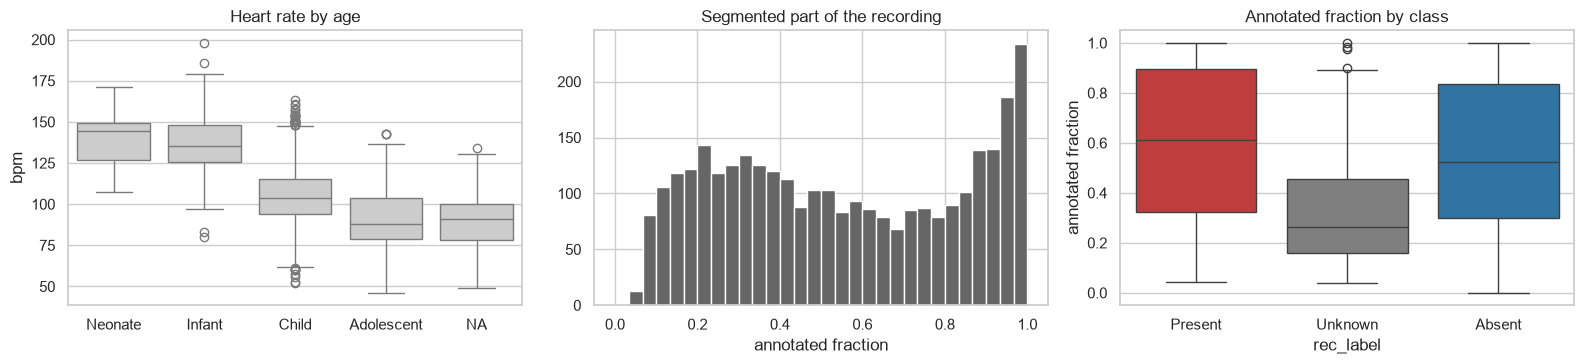

In [23]:
age = rec.patient_id.map(pat.Age).fillna('NA')
order = ['Neonate', 'Infant', 'Child', 'Adolescent', 'NA']
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.boxplot(x=age, y=rec.heart_rate, order=[o for o in order if o in set(age)], ax=ax[0], color='0.8')
ax[0].set(xlabel='', ylabel='bpm', title='Heart rate by age')
rec.ann_frac.hist(bins=30, ax=ax[1], color='0.4'); ax[1].set(xlabel='annotated fraction', title='Segmented part of the recording')
sns.boxplot(x=rec.rec_label, y=rec.ann_frac, order=CLASSES, palette=PALETTE, ax=ax[2])
ax[2].set(xlabel='rec_label', ylabel='annotated fraction', title='Annotated fraction by class')
plt.tight_layout(); save('segmentation_stats'); plt.show()

Now the key question: **is there more energy in systole when there is a murmur?**
For each recording we compute the mean power of the filtered signal (25–1000 Hz) in each phase.
We normalise by the power of S1, which removes the effect of each recording's volume.

  0%|          | 0/3163 [00:00<?, ?it/s]

  0%|          | 0/3163 [00:00<?, ?it/s]

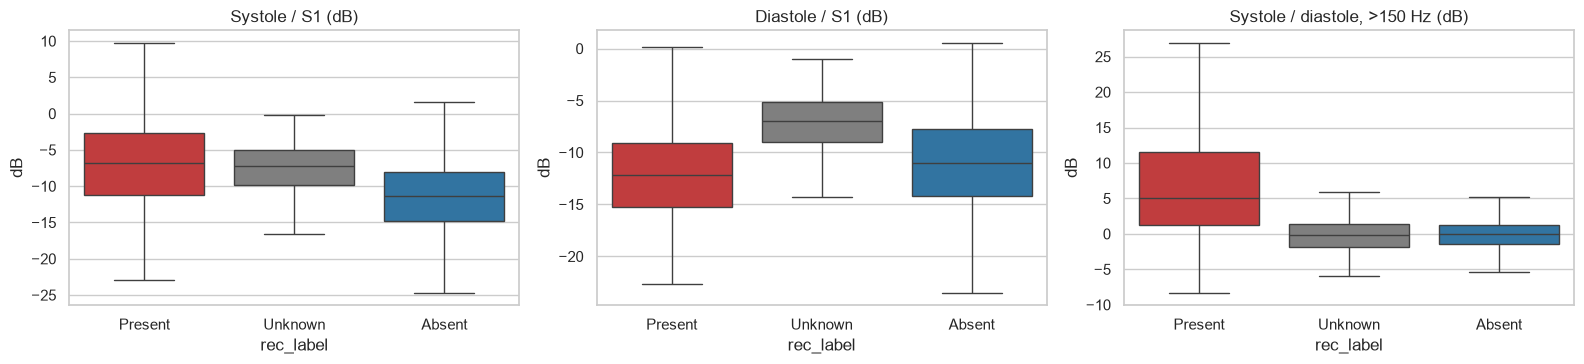

,sys_S1_db,dia_S1_db,sys_dia_hf_db
rec_label,,,
Present,-6.8,-12.2,5.1
Unknown,-7.3,-7.0,-0.1
Absent,-11.4,-11.0,0.0


In [24]:
def phase_power(path, seg, f_low=None):
    y = F.load_audio(path)
    if f_low:  # high-frequency component (murmurs are higher-pitched than S1/S2)
        y = ss.sosfiltfilt(ss.butter(4, f_low, 'highpass', fs=F.AUDIO.sr, output='sos'), y)
    sr, out = F.AUDIO.sr, {}
    for k, name in [(1, 'S1'), (2, 'systole'), (3, 'S2'), (4, 'diastole')]:
        s = seg[seg.state == k]
        seg_pow = [np.mean(y[int(a * sr):int(b * sr)] ** 2) for a, b in zip(s.start, s.end) if b - a > 0.01]
        out[name] = np.median(seg_pow) if seg_pow else np.nan
    return out

pp = pd.DataFrame([phase_power(p, load_segmentation(r)) for p, r in tqdm(zip(rec.path, rec.recording), total=len(rec))], index=rec.index)
pp_hf = pd.DataFrame([phase_power(p, load_segmentation(r), f_low=150) for p, r in tqdm(zip(rec.path, rec.recording), total=len(rec))], index=rec.index)
rec['sys_S1_db'] = 10 * np.log10(pp.systole / pp.S1)
rec['dia_S1_db'] = 10 * np.log10(pp.diastole / pp.S1)
rec['sys_dia_hf_db'] = 10 * np.log10(pp_hf.systole / pp_hf.diastole)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, t in zip(ax, ['sys_S1_db', 'dia_S1_db', 'sys_dia_hf_db'],
                     ['Systole / S1 (dB)', 'Diastole / S1 (dB)', 'Systole / diastole, >150 Hz (dB)']):
    sns.boxplot(x=rec.rec_label, y=rec[col], order=CLASSES, palette=PALETTE, ax=a, showfliers=False)
    a.set(xlabel='rec_label', ylabel='dB', title=t)
plt.tight_layout(); save('phase_energy_by_class'); plt.show()
display(rec.groupby('rec_label')[['sys_S1_db', 'dia_S1_db', 'sys_dia_hf_db']].median().reindex(CLASSES).round(1))

**Reading.**
- Heart rate decreases with age (median ≈ 103 bpm, minimum 46 bpm). A 4 s window holds **~7 cycles at the median**
  and **at least ~3** even at the slowest heart rate, which confirms the choice of window length.
- The segmentations cover only part of each recording: the annotator segmented a clean stretch. The rest may be noisier.
- In recordings with a murmur, **systole has much more relative energy** (vs S1 and vs diastole, especially above 150 Hz),
  while diastole changes little. This matches the clinical description of the murmurs, now measured on the signal.
  So a time-frequency representation showing what happens *between* S1 and S2 is what the CNN needs.
  For the MLP, spectral and band statistics capture the same thing globally.

## 7. Example signals and spectral content

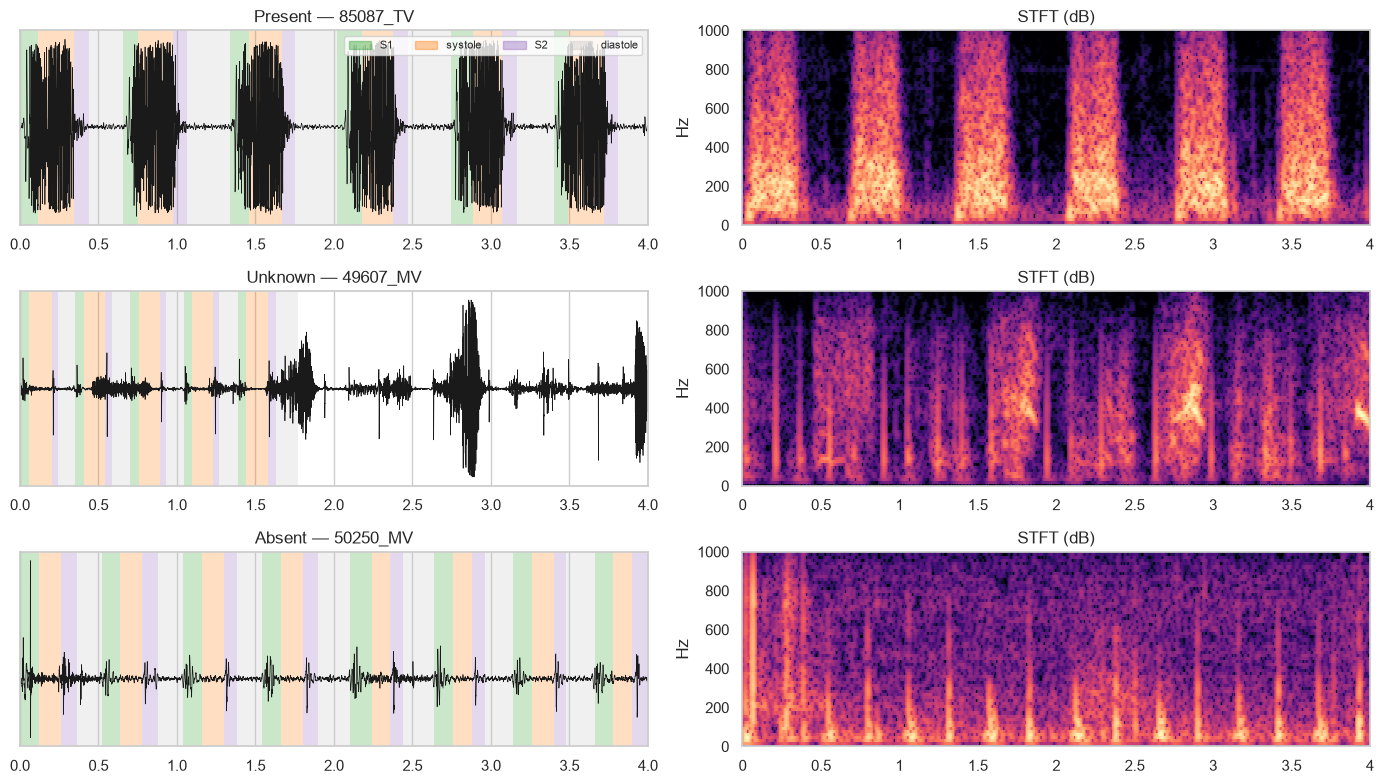

In [25]:
def show_example(r, ax_wave, ax_spec, seconds=4):
    y = F.load_audio(r.path); sr = F.AUDIO.sr
    seg = load_segmentation(r.recording)
    t0 = seg[seg.state == 1].start.min() if (seg.state == 1).any() else 0  # start at an annotated S1
    y = y[int(t0 * sr):int((t0 + seconds) * sr)]
    t = np.arange(len(y)) / sr
    ax_wave.plot(t, y, lw=.5, color='k')
    colors = {1: '#2ca02c', 2: '#ff7f0e', 3: '#9467bd', 4: '#c7c7c7'}
    for a, b, s in seg[(seg.end > t0) & (seg.start < t0 + seconds)].itertuples(index=False):
        if s in colors: ax_wave.axvspan(max(a - t0, 0), min(b - t0, seconds), color=colors[s], alpha=.25, lw=0)
    ax_wave.set(xlim=(0, seconds), title=f'{r.rec_label} — {r.recording}', yticks=[])
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=256, hop_length=16)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=16, x_axis='time', y_axis='linear', ax=ax_spec, cmap='magma', vmin=-70)
    ax_spec.set(ylim=(0, 1000), xlabel='', title='STFT (dB)')

# illustrative examples: the Present with the most systolic energy (>150 Hz), the Unknown with the smallest
# segmented part (the annotator could only segment a short stretch) and a median Absent
candidates = rec[rec.n_cycles.gt(3)]
examples = [candidates[candidates.rec_label == 'Present'].sort_values('sys_dia_hf_db').iloc[-1],
            candidates[candidates.rec_label == 'Unknown'].sort_values('ann_frac').iloc[0],
            candidates[candidates.rec_label == 'Absent'].sort_values('sys_dia_hf_db').iloc[len(candidates[candidates.rec_label == 'Absent']) // 2]]
fig, axes = plt.subplots(3, 2, figsize=(14, 8))
for r, (a1, a2) in zip(examples, axes): show_example(r, a1, a2)
from matplotlib.patches import Patch
axes[0, 0].legend(handles=[Patch(color=c, alpha=.4, label=l) for c, l in
                           zip(['#2ca02c', '#ff7f0e', '#9467bd', '#c7c7c7'], ['S1', 'systole', 'S2', 'diastole'])],
                  ncol=4, loc='upper right', fontsize=8)
plt.tight_layout(); save('example_signals'); plt.show()

For each recording we compute the mean spectrum (Welch, normalised signal) and look at the average per class:

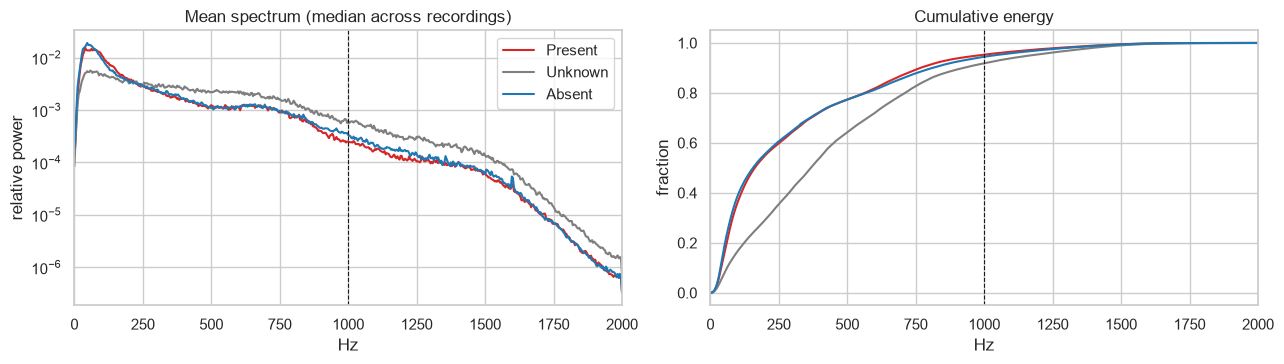

Present  50%/90%/99% of the energy below [164, 769, 1414] Hz
Unknown  50%/90%/99% of the energy below [367, 925, 1496] Hz
Absent   50%/90%/99% of the energy below [156, 812, 1433] Hz


In [26]:
specs = {}
for c in CLASSES:
    paths = rec[rec.rec_label == c].path
    paths = paths.sample(min(len(paths), 150), random_state=0)  # sample, for speed
    ps = []
    for p in paths:
        y, sr = librosa.load(p, sr=None)
        f, pxx = ss.welch((y - y.mean()) / (y.std() + 1e-8), fs=sr, nperseg=1024)
        ps.append(pxx / pxx.sum())
    specs[c] = np.array(ps)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for c in CLASSES:
    m = np.median(specs[c], 0)
    ax[0].semilogy(f, m, color=PALETTE[c], label=c)
    ax[1].plot(f, np.cumsum(specs[c].mean(0)), color=PALETTE[c], label=c)
for a in ax: a.axvline(1000, ls='--', color='k', lw=.8); a.set(xlabel='Hz', xlim=(0, 2000))
ax[0].set(title='Mean spectrum (median across recordings)', ylabel='relative power'); ax[0].legend()
ax[1].set(title='Cumulative energy', ylabel='fraction')
plt.tight_layout(); save('spectrum_by_class'); plt.show()
for c in CLASSES:
    cum = np.cumsum(specs[c].mean(0))
    print(f'{c:8s} 50%/90%/99% of the energy below', [int(f[np.searchsorted(cum, q)]) for q in (.5, .9, .99)], 'Hz')

In the examples: the *Present* one shows continuous energy between S1 and S2 (orange band), absent in the *Absent* one.
The *Unknown* one has strong, irregular noise that hides the cycle (and only part of the recording was segmented).

**Reading.**
- S1 and S2 concentrate below ~150 Hz. Murmurs spread energy across systole up to a few hundred Hz.
  Above ~1 kHz there is mostly noise (friction, speech, crying).
- Hence the **25–1000 Hz band-pass filter**: below 25 Hz there is drift and movement, above 1 kHz there is little useful signal.
  For the same reason the mel spectrogram only goes up to 1000 Hz: it concentrates the mel bands where the information is.
- *Unknown* recordings have a spectrum shifted towards higher frequencies, consistent with more noise.

## 8. Signal quality: what makes *Unknown* different?
*Unknown* means the physician could not decide, often because of noise. Two simple measures per recording:
- **periodicity**: peak of the autocorrelation of the energy envelope between 0.3 and 1.5 s (40–200 bpm).
  High for a clean heart sound, low with noise.
- **spikes/artefacts**: fraction of samples with |z| > 6 (stethoscope knocks, clicks).

quality:   0%|          | 0/3163 [00:00<?, ?it/s]

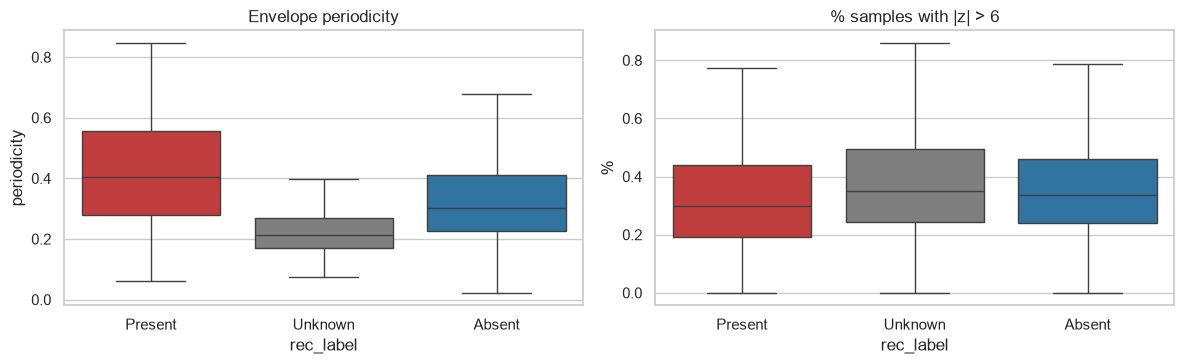

,periodicity,spikes
rec_label,,
Present,0.405,0.003
Unknown,0.212,0.004
Absent,0.301,0.003


In [27]:
def quality(path):
    y = F.load_audio(path)
    w = y[:F.AUDIO.window_len * 5]  # first 20 s
    per = np.median([F.envelope_periodicity(x)[0] for x in F.split_windows(w)[0]])
    return {'periodicity': per, 'spikes': np.mean(np.abs(y) > 6)}

q = pd.DataFrame([quality(p) for p in tqdm(rec.path, desc='quality')], index=rec.index)
rec = rec.join(q)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(x=rec.rec_label, y=rec.periodicity, order=CLASSES, palette=PALETTE, ax=ax[0], showfliers=False)
ax[0].set(title='Envelope periodicity', xlabel='rec_label')
sns.boxplot(x=rec.rec_label, y=100 * rec.spikes, order=CLASSES, palette=PALETTE, ax=ax[1], showfliers=False)
ax[1].set(title='% samples with |z| > 6', xlabel='rec_label', ylabel='%')
plt.tight_layout(); save('signal_quality'); plt.show()
display(rec.groupby('rec_label')[['periodicity', 'spikes']].median().reindex(CLASSES).round(3))

**Reading.** *Unknown* recordings are less periodic, i.e. the cardiac cycle is harder to make out.
That is why we include envelope periodicity in the MLP features. In the CNN the same information is implicit
in the spectrogram: the regularity of S1/S2 over time. Even so, *Unknown* will be the hardest class
(it is the smallest one and is defined as "nobody could decide").

We do not discard noisy recordings: the hidden set will have them too, and the model must be able to answer *Unknown*.

## 9. Conclusions for the pre-processing
What the exploration decides:

| observation (section) | decision |
|---|---|
| only the `.wav` is a signal; CSV columns are labels, annotations or demographics (§0) | **models take only the phonocardiogram as input** |
| WA penalises missing *Present*; *Absent* dominates (§1) | class weights in the loss and a threshold tuned on validation |
| same child in both campaigns, labels sometimes differ (§2) | group split (already in `split.csv`); accept an *accuracy* ceiling |
| systolic, faint murmurs between S1 and S2 (§3, §6) | windows with complete cycles and ~10 ms time resolution |
| everything at 4 kHz, 5–65 s, ~4 locations per patient (§4) | no resampling; **4 s windows** (2 s hop) instead of crop/pad |
| ~1 in 5 *Present* recordings without a murmur at that location (§5) | train with **`rec_label`**; aggregate per patient with the max of P(Present) |
| heart rate between 46 and ~170 bpm, median 103 (§6) | 4 s is enough for ≥ 3 cycles (~7 at the median) |
| useful energy < 1 kHz, noise above (§7) | **25–1000 Hz band-pass**; mel up to 1000 Hz |
| *Unknown* = noisy, not very periodic (§8) | periodicity feature in the MLP; absolute dB level in the CNN (no min-max) |
| segmentations only cover part of each recording and may be missing in the hidden data (§0, §6) | **do not use the .tsv as input** |